<a href="https://colab.research.google.com/github/nothyfaria5-netizen/Fonte_de_Informacao_e_Banco_de_Dados/blob/main/Sorvete.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sakshisatre/ice-cream-sales-dataset")

print("Path to dataset files:", path)

100%|██████████| 2.09k/2.09k [00:00<00:00, 2.72MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/sakshisatre/ice-cream-sales-dataset/versions/1


In [ ]:
import os
import pandas as pd

# Listar os arquivos no diretório para identificar o arquivo de dados
files = os.listdir(path)
print("Arquivos no diretório:", files)

# Encontrar o primeiro arquivo CSV disponível
csv_files = [f for f in files if f.endswith('.csv')]
if csv_files:
    csv_path = os.path.join(path, csv_files[0])
    df = pd.read_csv(csv_path)
    print(f"\nExibindo as primeiras linhas de: {csv_files[0]}")
    display(df.head())
else:
    print("Nenhum arquivo CSV encontrado no diretório.")

Arquivos no diretório: ['Ice Cream.csv']

Exibindo as primeiras linhas de: Ice Cream.csv


,Temperature,Revenue
0,24.6,535
1,26.1,626
2,27.8,661
3,20.6,488
4,11.6,317


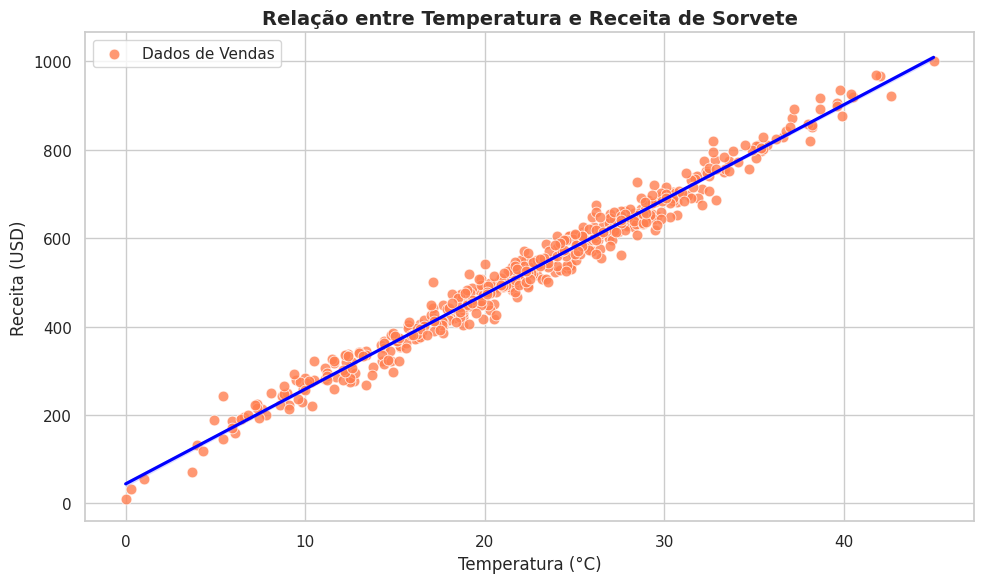

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar o estilo do gráfico
sns.set_theme(style="whitegrid")

# Criar a figura
plt.figure(figsize=(10, 6))

# Criar o gráfico de dispersão
sns.scatterplot(data=df, x='Temperature', y='Revenue', color='coral', alpha=0.8, edgecolor='w', s=60, label='Dados de Vendas')

# Adicionar linha de tendência para visualizar melhor a relação
sns.regplot(data=df, x='Temperature', y='Revenue', scatter=False, color='blue', line_kws={'label': 'Linha de Tendência'})

# Configurar títulos e rótulos
plt.title('Relação entre Temperatura e Receita de Sorvete', fontsize=14, fontweight='bold')
plt.xlabel('Temperatura (°C)', fontsize=12)
plt.ylabel('Receita (USD)', fontsize=12)
plt.legend(loc='upper left')

# Exibir o gráfico
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Definir as variáveis de entrada (X) e saída (y)
X = df[['Temperature']]
y = df['Revenue']

# Dividir os dados em conjuntos de treino (80%) e teste (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Inicializar e treinar o modelo de regressão linear
model = LinearRegression()
model.fit(X_train, y_train)

# Fazer previsões usando o conjunto de teste
y_pred = model.predict(X_test)

# Avaliar o modelo
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
coeficiente = model.coef_[0]
intercepto = model.intercept_

print("=== Resultados do Modelo de Regressão Linear ===")
print(f"Coeficiente (Inclinação): {coeficiente:.4f}")
print(f"Intercepto: {intercepto:.4f}")
print(f"Coeficiente de Determinação (R²): {r2:.4f}")
print(f"Erro Quadrático Médio (MSE): {mse:.4f}")
print(f"Raiz do Erro Quadrático Médio (RMSE): {np.sqrt(mse):.4f}")

=== Resultados do Modelo de Regressão Linear ===
Coeficiente (Inclinação): 21.3840
Intercepto: 46.1783
Coeficiente de Determinação (R²): 0.9772
Erro Quadrático Médio (MSE): 652.4938
Raiz do Erro Quadrático Médio (RMSE): 25.5440
